### <b>Section 0: FlyFinder set up</b>

In [11]:
#@title Mount google drive

from google.colab import drive
drive.mount('/content/drive')
import os

%cd "/content/drive/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive


In [12]:
#@title Install dependencies
!pip install img2pdf
!pip install mpi4py

In [13]:
#@title FlyFinder directory location
fly_finder_dir="MyDrive/flyFinder-test/" #@param {type: "string"}
train_dir="train_1p" #@param {type: "string"}
test_dir="test_1p" #@param {type: "string"}

fly_finder_dir+="/"
train_dir+="/"
test_dir+="/"


%cd $fly_finder_dir
%reload_ext rpy2.ipython
!Rscript dependencies.R

/content/drive/MyDrive/flyFinder-test


### <b>Section 1: Training the classifier</b>

### Importing FlyFinder Functions 

In [14]:
#@title Importing FlyFinder Function
from FF_utils import *

<a name="l1"></a>
### 1.1. Setting up initial parameters 

In [15]:
#@title The parameters for drawing
# Defining the colors
blue=(0,0,255); 
red=(255,0,0); 
magenta=(255,0,255); 

# Setting the line, point and figure size
# if pen=5 or less and the bottom lines is not visible, set it to 10
pen=5  #@param {type : "raw"}
point=15 #@param {type : "raw"}
figSize=5 #@param {type : "raw"}

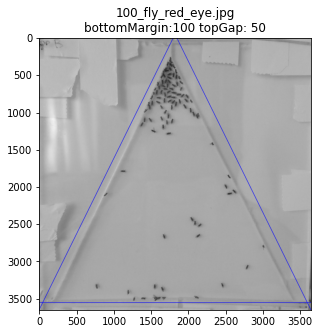

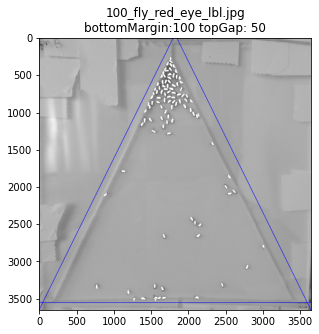

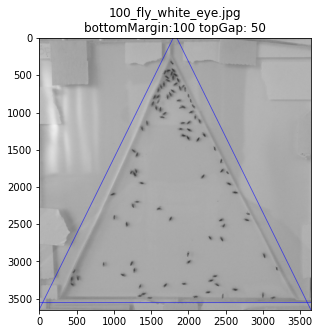

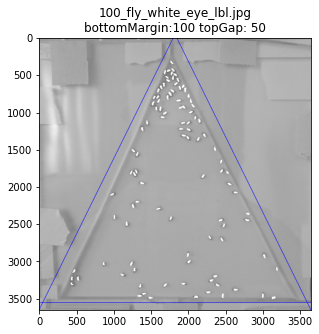

In [17]:
#@title Cropping the sides, masking the background and visualization for image files for training a model

#Cropping the input image if necessary (pxl)
cropLeft4=0 #@param {type : "raw"}
cropRight4=0 #@param {type : "raw"}
cropTop4=0 #@param {type : "raw"}
cropBottom4=0 #@param {type : "raw"}

# Applying the mask:
# bottomMargin : correspond to the marging applied to the bottom of the image
# topgap : correspond to the distance between the two sides-triangle lines (at the top of the picture)   

bottomMargin4=100 #@param {type : "raw"}
topGap4=50 #@param {type : "raw"}

## Visualization
## imagPath_="train_4p/"
imagPath_=train_dir

displayImages = True #@param {type:"boolean"}


def display_img(booln):
  if booln:
    viewImageMargins1Panel(imagPath=train_dir, bottomMargin=bottomMargin4, 
                           topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, 
                           cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, 
                           figSize=figSize, pen_=pen)


## Visualization
display_img(displayImages)
# imagPath_="/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/train_1p/"
#viewImageMargins1Panel(imagPath=imagPath_, bottomMargin=bottomMargin4, topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, figSize=figSize, pen_=pen) 

<a name="l2"></a>
### 1.2. Training the random forest classifier

In [18]:
#@title Training settings and train a machine learning model 

modelName = "test_2022_01_27"  #@param {type:"string"}
plateType = "1Panel"  #@param {type:"string"}
nGaussianFilters=40  #@param {type:"raw"}
nMedianFilters=10  #@param {type:"raw"}
nEstimators = 30  #@param {type:"raw"}
bottomMargin = 100  #@param {type:"raw"}
topGap = 50  #@param {type:"raw"}
cropLeft = 0  #@param {type:"raw"}
cropRight = 0  #@param {type:"raw"}
cropTop = 0  #@param {type:"raw"}
cropBottom = 0  #@param {type:"raw"}
runTrainig = True #@param {type:"boolean"}


def train_warpper(modelName, plateType, nGaussianFilters,
                  nMedianFilters, nEstimators, bottomMargin,
                  topGap, cropLeft, cropRight,
                  cropTop, cropBottom, runTrainig
                  ):
  
  cmd = f"! python3 FlyFinder_train.py --modelName {modelName} \
                            --plateType {plateType} \
                            --nGaussianFilters={nGaussianFilters} \
                            --nMedianFilters={nMedianFilters} \
                            --nEstimators {nEstimators} \
                            --bottomMargin {bottomMargin} \
                            --topGap {topGap} \
                            --cropLeft {cropLeft} \
                            --cropRight {cropTop} \
                            --cropTop {cropTop} \
                            --cropBottom {cropBottom} \
                            --inPath {train_dir} "
  if runTrainig:
    # print(cmd)
    os.system(cmd)

train_warpper(modelName, plateType, nGaussianFilters,
                  nMedianFilters, nEstimators, bottomMargin,
                  topGap, cropLeft, cropRight,
                  cropTop, cropBottom, runTrainig)



# ! python FlyFinder_train.py --modelName $modelName \
#                             --plateType $plateType \
#                             --nGaussianFilters=$nGaussianFilters \
#                             --nMedianFilters=$nMedianFilters \
#                             --nEstimators $nEstimators \
#                             --bottomMargin $bottomMargin \
#                             --topGap $topGap \
#                             --cropLeft $cropLeft \
#                             --cropRight $cropTop \
#                             --cropTop $cropTop \
#                             --cropBottom $cropBottom \
#                             --inPath $train_dir 



#! python FlyFinder_train.py --modelName "M1Panel_GF40_MF10_Es30_mar100_topG50_RFC" \
#                            --plateType 1Panel \
#                            --nGaussianFilters=40 \
#                             --nMedianFilters=10 \
#                            --nEstimators 30 \
#                            --bottomMargin 100 \
#                            --topGap 50 \
#                            --cropLeft 0 \
#                            --cropRight 0 \
#                            --cropTop 0 \
#                            --cropBottom 0 \
#                            --inPath /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/train_4p/

<b>- The resulting model has:</b><br>
Accuracy = 0.993
Training duration =  16.49 min 

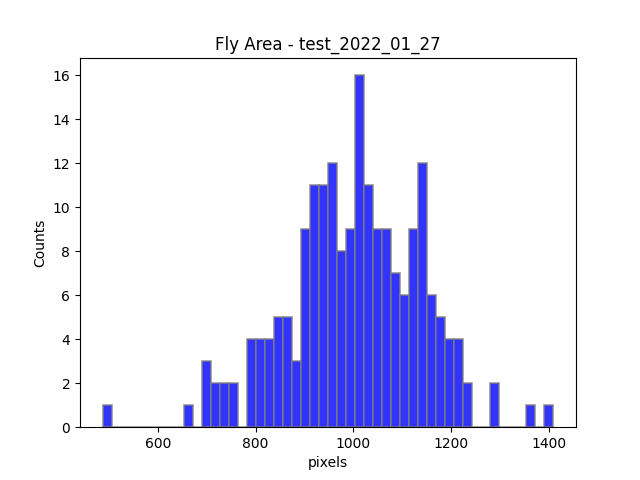

In [19]:
#@title Viewing the flyArea density plot - optional
from IPython.display import Image

density_png_file = f"RFC_model/{modelName}_flyArea.png"
Image(filename=density_png_file, width=400, height=400)
# Image(filename="RFC_model/google_colab_test_flyArea.png", width=400, height=400)



#from IPython.display import Image
#Image(filename="/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/RFC_model/M1Panel_GF40_MF10_Es30_mar100_topG50_RFC_flyArea.png", width=400, height=400)

### <b>Section 2: Segmentation of images</b>

<a name="l3"></a>
### 2.1. Performing the first segmentation 


 Viewing the script parameters of the script that perfroms the first segmentation:

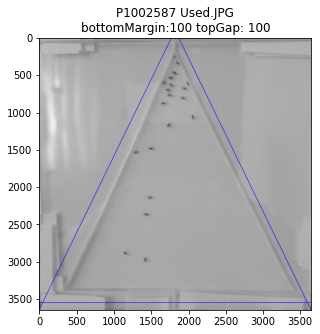

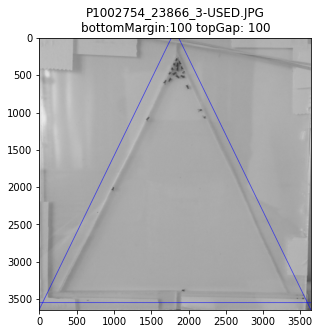

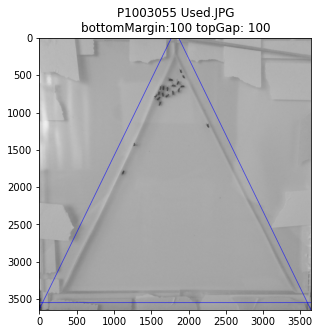

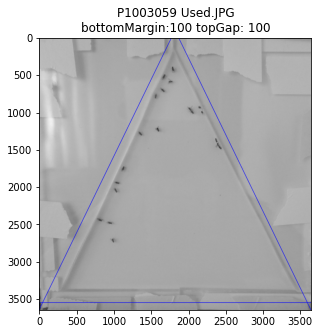

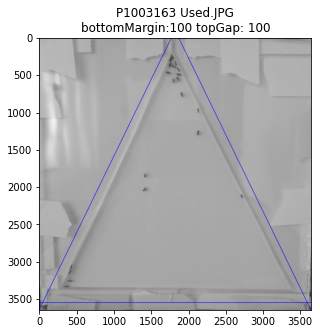

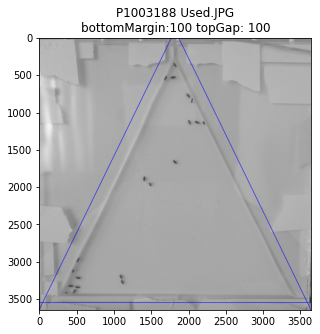

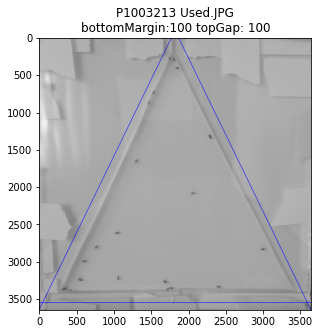

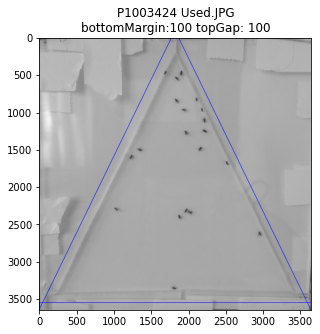

In [20]:
#@title Cropping the input image if necessary and visualization

cropLeft4=0 #@param {type : "raw"}
cropRight4=0 #@param {type : "raw"}
cropTop4=0 #@param {type : "raw"}
cropBottom4=0 #@param {type : "raw"}

# Applying the mask:
# bottomMargin : correspond to the marging applied to the bottom of the image
# topgap : correspond to the distance between the two sides-triangle lines (at the top of the picture)   

bottomMargin4=100 #@param {type : "raw"}
topGap4=100 #@param {type : "raw"}


displayImages = True #@param {type:"boolean"}

def display_img(booln):
  if booln:
    viewImageMargins1Panel(imagPath=test_dir, bottomMargin=bottomMargin4, 
                           topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, 
                           cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, 
                           figSize=figSize, pen_=pen)

## Visualization
#viewImageMargins4Panel(imagPath=test_dir, bottomMargin=bottomMargin4, topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, figSize=figSize, pen_=pen) 
display_img(displayImages)

In [21]:

#@title Running the first segmentation
#modelName = "M4Panel_GF40_MF10_Es30_mar100_topG50_RFC" #@param {type:"string"}
plateType = "1panel" #@param {type:"string"}
minArea =  70#@param {type:"raw"}
maxArea =  350#@param {type:"raw"}
nGaussianFilters = 40 #@param {type:"raw"}
nMedianFilters = 10 #@param {type:"raw"}
nEstimators = 30 #@param {type:"raw"}
bottomMargin =  200#@param {type:"raw"}
topGap =  150#@param {type:"raw"}
cropLeft = 0 #@param {type:"raw"}
cropRight = 0 #@param {type:"raw"}
cropTop = 0 #@param {type:"raw"}
cropBottom = 0 #@param {type:"raw"}
numFlies =  20#@param {type:"raw"}


! mpiexec --allow-run-as-root -np 4  python FlyFinder_first_segmentation.py --modelName $modelName \
                                                        --plateType $plateType \
                                                        --minArea $minArea \
                                                        --maxArea $maxArea \
                                                        --nGaussianFilters $nGaussianFilters \
                                                        --nMedianFilters $nMedianFilters \
                                                        --bottomMargin $bottomMargin \
                                                        --topGap $topGap \
                                                        --cropLeft $cropLeft \
                                                        --cropRight $cropRight \
                                                        --cropTop $cropTop   \
                                                        --cropBottom $cropBottom \
                                                        --numFlies $numFlies  \
                                                        --inPath $test_dir \


#! mpiexec -n 25  python FlyFinder_first_segmentation.py --modelName M1Panel_GF40_MF10_Es30_mar100_topG50_RFC \
#                                                        --plateType 1Panel \
#                                                        --minArea 120 \
#                                                        --maxArea 550 \
#                                                        --nGaussianFilters 40 \
#                                                        --nMedianFilters 10 \
#                                                        --bottomMargin 220 \
#                                                        --topGap 150 \
#                                                        --cropLeft 0 \
#                                                        --cropRight 0 \
#                                                        --cropTop 0 \
#                                                       --cropBottom 0 \
#                                                        --numFlies 20 \
#                                                        --inPath /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_1p/


-* FlyFinder_v1.0 *-




*--- Running FlyFinder Random Forest-based segmantation : core n. 00 ---*

-----------------------------------------------------------------------------------------------

Started time: 2022-01-28 16:10:37.893749



Active path : /content/drive/MyDrive/flyFinder-test/test_1p/

Settings :
Namespace(bottomMargin=200, cropBottom=0, cropLeft=0, cropRight=0, cropTop=0, inPath='test_1p/', maxArea=350, minArea=70, modelName='test_2022_01_27', nGaussianFilters=40, nMedianFilters=10, numFlies=20, plateType='1panel', topGap=150)

Loading the RFC model. Please wait ... 

  Model loaded successfully: /content/drive/MyDrive/flyFinder-test/RFC_model/test_2022_01_27.pkl


  Number of images : 8

['P1002587 Used.JPG', 'P1002754_23866_3-USED.JPG', 'P1003055 Used.JPG', 'P1003059 Used.JPG', 'P1003163 Used.JPG', 'P1003188 Used.JPG', 'P1003213 Used.JPG', 'P1003424 Used.JPG']

P1002587 Used.JPG
 Proc_00
 Generating feature matrix using different kernel functions (Gaussian, and Medi

##### <a name="l4"></a>
### 2.2. Manual editing the failed images


The output after segmentation contains two directories:<br>
<b>FlyFinder_v1.0/test_1p/out</b> for well segmented images and <b>FlyFinder_v1.0/test_1p/outf</b> for failed images.<br> 
For a quick review of all figures it is recommended to open and check the <b>out.pdf</b> and <b>outf.pdf</b> located in <b>out</b> and <b>outf</b> directories respectively. <br> 

The user must first check for any potential failed images in the out directory and move both the .csv and .jpg files to the <br>
outf directory. All .jpg images in the outf directory must then be manually edited. Editing involves ensuring all flies are <br>
correctly identified by a white 10px by 10px box and background noise (incorrectly labeled white boxes) deleted/blackened. Image<br>
editing can be performed using Fiji or any photo editing software.


In [ ]:
!ls $test_dir/outf

 outf.pdf			     'p1003163 used_flies_22.jpg'
 p1002754_23866_3-used_flies_21.csv  'p1003213 used_flies_19.csv'
 p1002754_23866_3-used_flies_21.jpg  'p1003213 used_flies_19.jpg'
'p1003163 used_flies_22.csv'


<a name="l5"></a>
### 2.3. Performing the second segmentation 

In [22]:
#@title The second segmentation 
! mpiexec -n 4  --allow-run-as-root  python3 FlyFinder_second_segmentation.py --inPath $test_dir/outf


-* FlyFinder_v1.0 *-


Performing segmantation for image where flies are marked with 10x10 pxl white points (squares)
----------------------------------------------------------------------------------------
Started time: 2022-01-28 16:25:39.689479



Active path : test_1p//outf/


Number of images 3


Error: the number of processors chosen is more than the images to segment!
Please use processor less or equal to than 3


<a name="l6"></a>
### 2.4. Creating the table of fly coordinates

A python script is used to compile one main table that combines all tables of  xy-coordinates of fly location from each image

In [23]:
#@title Creating the table of fly coordinates (Run this cell)

! python FlyFinder_maketable.py --inPath  $test_dir


* RFC segmantation : Number of tables = 5

p1002587 used_flies_20.csv
p1003055 used_flies_20.csv
p1003059 used_flies_20.csv
p1003188 used_flies_20.csv
p1003424 used_flies_20.csv

No csv tables found in test_1p/outf/out_ps/ 
 please check your input.

The combined table path 
test_1p/FinalTable.csv 

*---  FlyFinder final table generated successfully âœ“---*




<a name="l7"></a>
### 2.5. Calculating the nearest neighbors distances

An R command computes the first, second, third and average nearest neighbor distances, compiling them into final tables and figures.

In [24]:
#@title Calculating the nearest neighbors distance - Run this cell
imgwidth = 3648 #@param {type:"raw"}
imgheight =  3648#@param {type:"raw"}

! Rscript Neighbor_distances.R --inPath  $test_dir --imgWidth $imgwidth --imgHeight $imgheight




 * ----  Computing nearest neigbor distance  ---- *

 Path of x-y coordiate table :  test_1p/
 Images width  (pxl) :  3648
 Images hieght (pxl) :  3648
p1002587 used_flies_20.jpg 
p1003055 used_flies_20.jpg 
p1003059 used_flies_20.jpg 
p1003188 used_flies_20.jpg 
p1003424 used_flies_20.jpg 
Generating final pdf of figures

 * ----  Successfuly completed!  ---- *



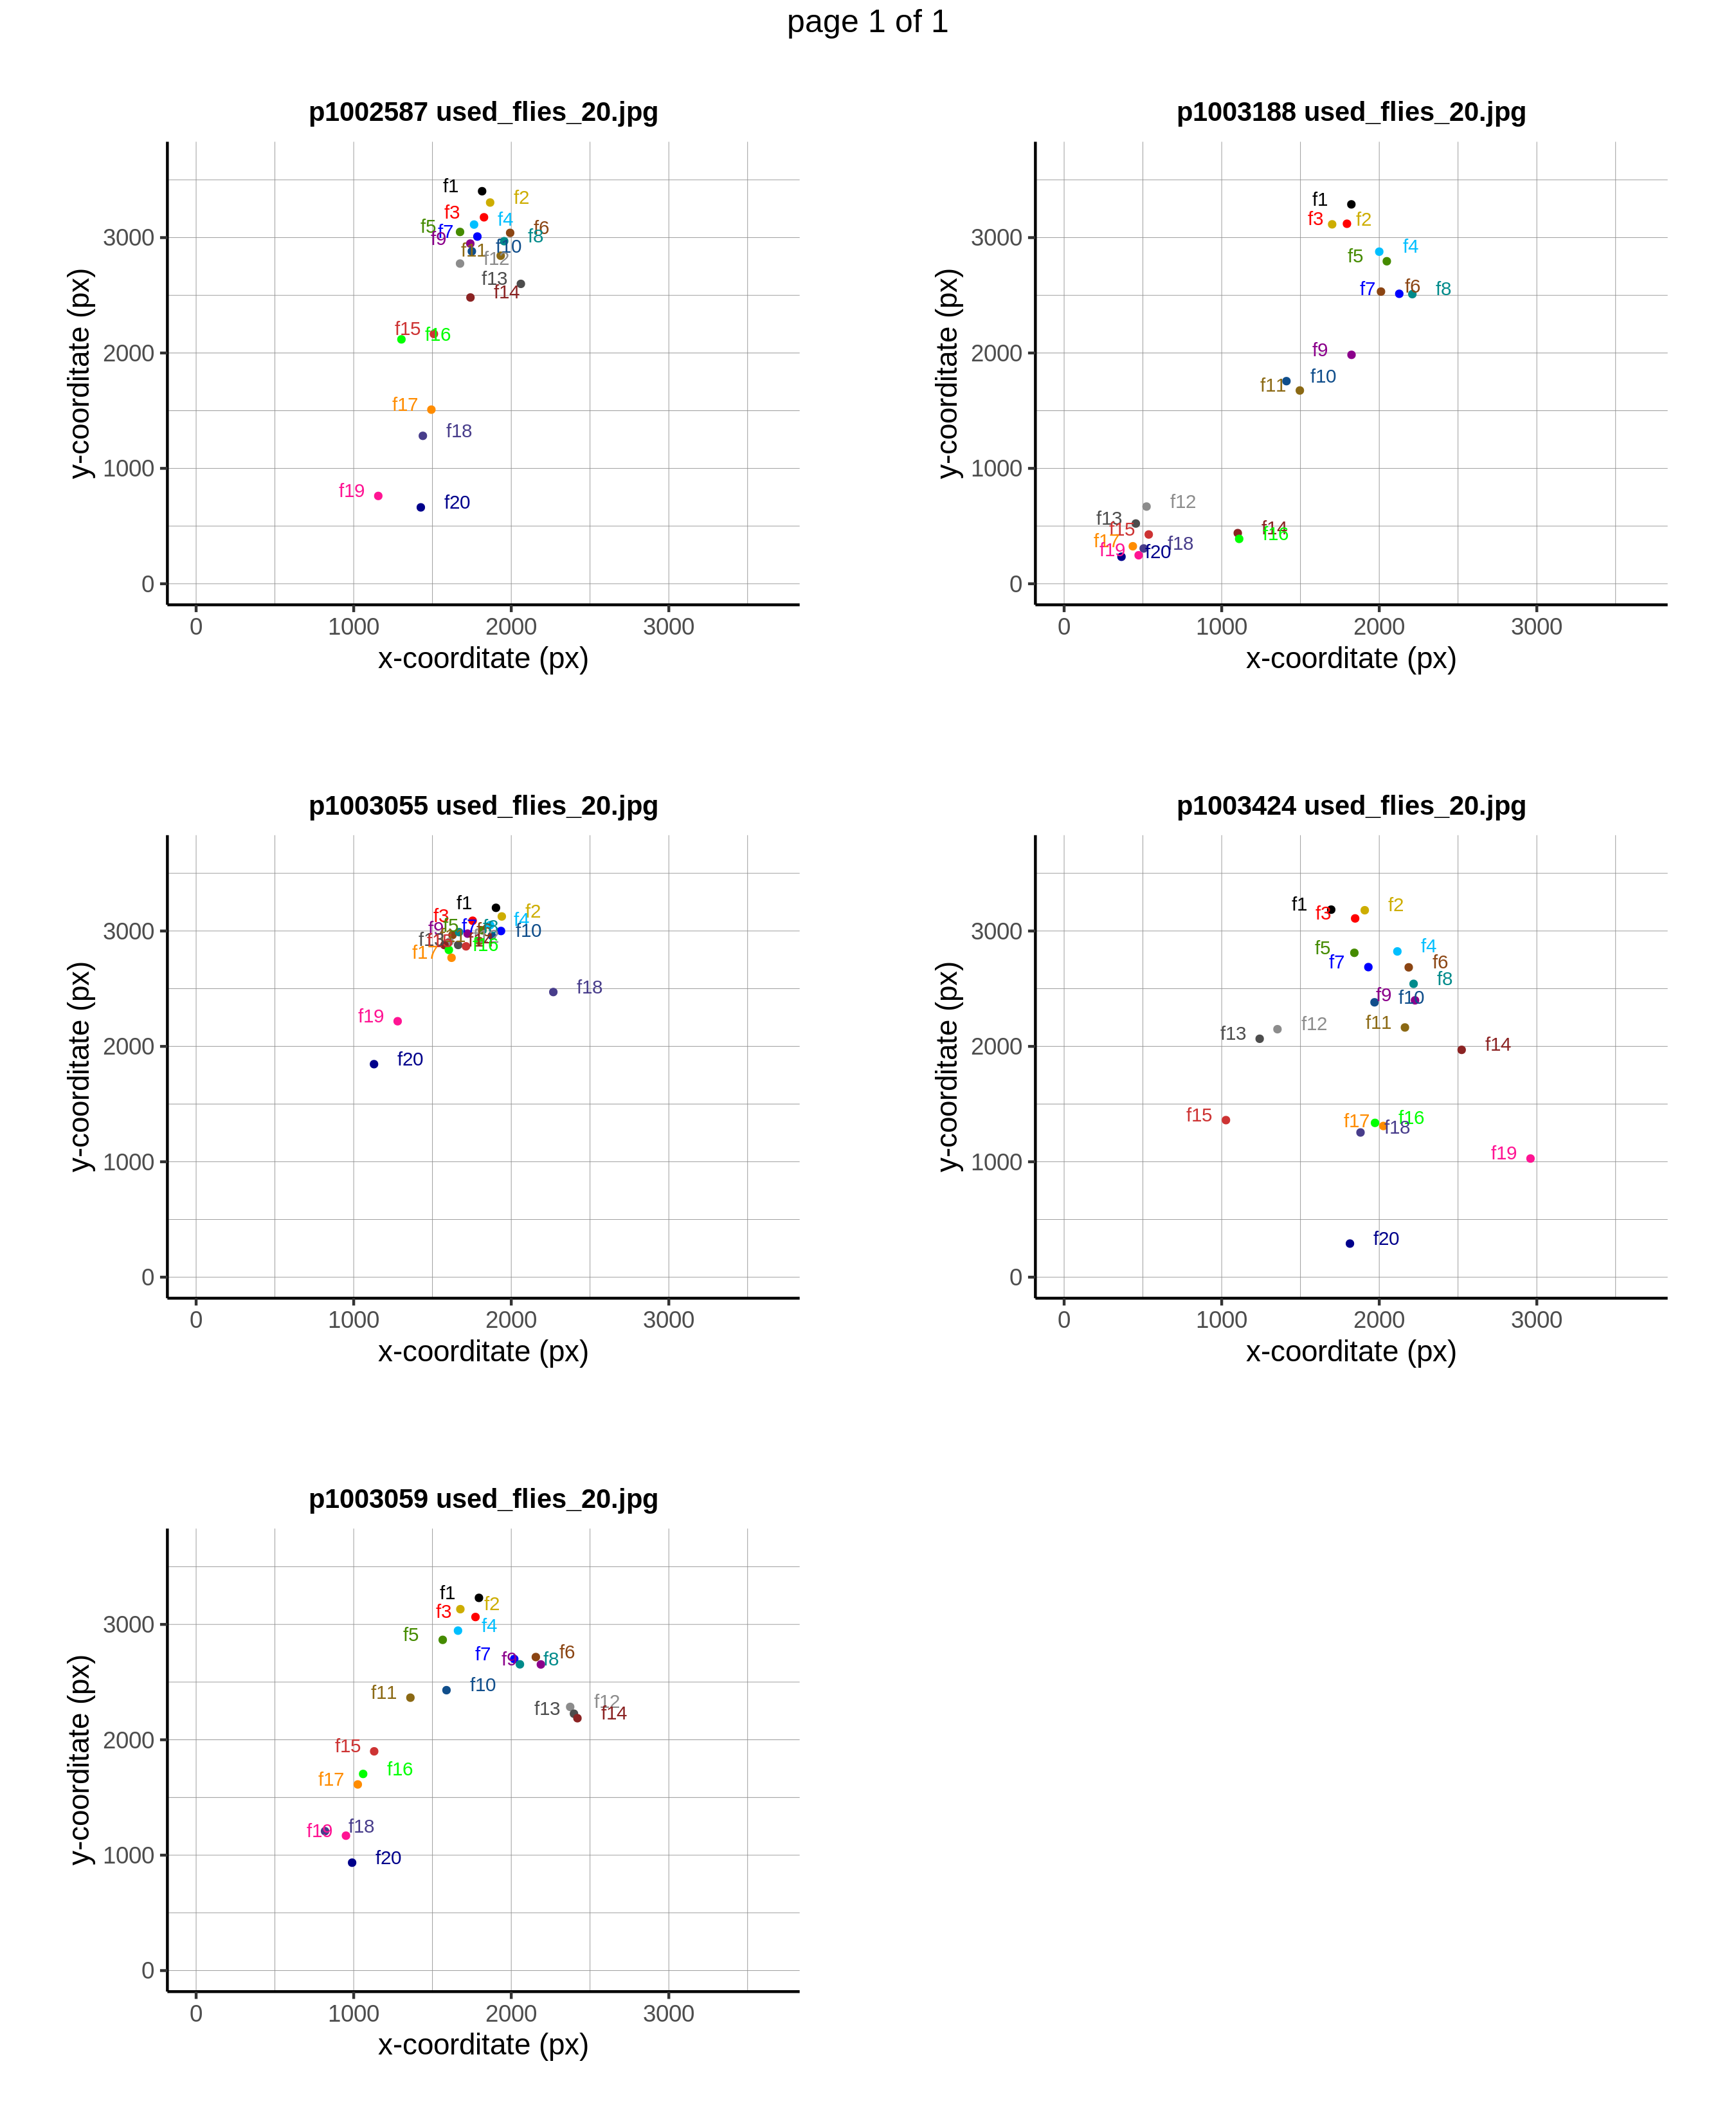

In [25]:
#@title Displaying the fly coordinate figure

from IPython.display import Image
png_file=f"{test_dir}/FinalFigures.dist.png"
Image(filename=png_file)

###   *   Here ends of the pipeline  *

## FlyFinder version 1.0 (1-panel images - Panasonic Camera )
This notebook provides the sequence of instructions and commands for training a random forest classifer <br>
used during segmentation. It also give instructions and the commands of the whole process of segmentation.
<br><br>
If the model has been trained for a specific study setup, there will be no need to retrain, the user can <br>
immediately proceed to section 2 for first segmentation.

<u> Used camera model:</u><br>
Panosonic DC-ZS200<br>
<u>Settings</u>:<br> 
Aspect-ration 1:1<br>
Picture size: 3648 X 3648 pxl<br>
Filter settings: monochrome<br>
Use a 10-second selt timer for three pictures<br>


### Section 1: Training the classifier

- [1.1. Setting up initial parameters](#l1)
   
- [1.2. Training the random forest classifier](#l2)

### Section 2: Segmentation of images
   
- [2.1. Performing the first segmentation](#l3)

- [2.2. Manual editing the failed images ](#l4)

- [2.3. Performing the second segmentation](#l5)

- [2.4. Creating the table of fly coordinates ](#l6)

- [2.5. Calculating the nearest neighbors distances](#l7)
 

<b>  - Cropping the sides, masking the background and visualization (1-panel images): </b><br>
The <b>cropLeft</b>, <b>cropRight</b>, <b>cropTop</b> and <b>cropBottom</b> are used to crop the left, right,<br> 
top and  bottom sides the input images in case it is necessary.<br>
The <b>bottomMargin</b> and <b>topGap</b> parameters are used to demarcate the triangle such that the area inside the <br>
lines will be used while the area outside will be ignored. Different values can be tired to determine the best<br>
fit for a particular imaging setup. The demarcated pictures can be viewed in the next command

After getting the best values of <b>bottomMargin</b> and <b>topGap</b> that best demarcate the <br>
triangle (i.e bottomMargin=60 topGap=10), they will be used to traini either a 1 or 4Panel-based random forest classifier.<br>

We can first see the script parameters like this:

In [ ]:
#from FF_utils import *
! python FlyFinder_train.py --help


-* FlyFinder_v1.0 *-

usage: FlyFinder_train.py [-h] --modelName MODELNAME --plateType PLATETYPE
                          --nGaussianFilters NGAUSSIANFILTERS --nMedianFilters
                          NMEDIANFILTERS --nEstimators NESTIMATORS
                          --bottomMargin BOTTOMMARGIN --topGap TOPGAP
                          --cropLeft CROPLEFT --cropRight CROPRIGHT --cropTop
                          CROPTOP --cropBottom CROPBOTTOM --inPath INPATH

optional arguments:
  -h, --help            show this help message and exit
  --modelName MODELNAME
                        the name you want to give to your random forest
                        classifier.
  --plateType PLATETYPE
                        the 1 panel plate '1panel' or 4 panel plate '4panel'.
  --nGaussianFilters NGAUSSIANFILTERS
                        the number of gaussian filters. Default=40.
  --nMedianFilters NMEDIANFILTERS
                        the number of median filters. Default=40.
  --nEstimators N

<b>- Check if there are trained models:</b>

<b>- Viewing the directory of images used for segmentation: </b><br>
Note: the labelled image for training must have '_lbl' added to its name right before the '.jpg' file extension.

In [ ]:
! python FlyFinder_first_segmentation.py --help


-* FlyFinder_v1.0 *-

usage: FlyFinder_first_segmentation.py [-h] --modelName MODELNAME --plateType
                                       PLATETYPE --nGaussianFilters
                                       NGAUSSIANFILTERS --nMedianFilters
                                       NMEDIANFILTERS --bottomMargin
                                       BOTTOMMARGIN --topGap TOPGAP --cropLeft
                                       CROPLEFT --cropRight CROPRIGHT
                                       --cropTop CROPTOP --cropBottom
                                       CROPBOTTOM --maxArea MAXAREA --minArea
                                       MINAREA --numFlies NUMFLIES --inPath
                                       INPATH

optional arguments:
  -h, --help            show this help message and exit
  --modelName MODELNAME
                        the name of the random forest classifier to use.
  --plateType PLATETYPE
                        the 1 panel plate '1panel' or 4 panel plate '4pa

In [ ]:
! python FlyFinder_train.py models


-* FlyFinder_v1.0 *-

Available trained random forest classifiers:

M1Panel_GF40_MF10_Es30_mar100_topG50_RFC
M4Panel_GF40_MF10_Es30_mar100_topG50_RFC




In [ ]:
! python FlyFinder_first_segmentation.py models


-* FlyFinder_v1.0 *-

Avalable random forest classifiers:

M1Panel_GF40_MF10_Es30_mar100_topG50_RFC
M4Panel_GF40_MF10_Es30_mar100_topG50_RFC


